# NeuralDream: Multi-Subject EEG to Image DecodingMapping 17-channel EEG signals across **multiple subjects** to **768-d CLIP ViT-Large** space for zero-shot image retrieval & conditioned synthesis.**Dataset:** THINGS-EEG2 (Multi-Subject Pool: dynamically discovers all subjects `sub-01`, `sub-02`, etc.)- **Per-Subject Z-Scoring:** Zero-leakage standardization using individual subject training statistics.- **Multi-Subject Training Pool:** Pools training data across all available subjects into a unified encoder.- **Concept-Level Validation:** Grand-averaged 154-concept validation prototypes for architecture-aware grid search and early checkpointing.- **Multi-Subject Test Benchmark:** Evaluates predictions per subject and on cross-subject grand-averaged EEG.

In [1]:
# Install dependencies (uncomment if needed)
!pip install -q kagglehub torch torchvision transformers pillow scikit-learn matplotlib tqdm

In [2]:
import os
import json
import math
import shutil
import warnings
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm
from sklearn.metrics.pairwise import cosine_similarity

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from transformers import CLIPProcessor, CLIPModel

warnings.filterwarnings('ignore')

In [3]:
# Device: CUDA > MPS (Apple Silicon) > CPU
if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
else:
    DEVICE = torch.device('cpu')

print(f'PyTorch: {torch.__version__} | Device: {DEVICE}')

# Reproducibility Seed
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

PyTorch: 2.14.1+cu130 | Device: cuda


In [4]:
# Download latest version of dataset from Kaggle via kagglehub
import kagglehub

path = kagglehub.dataset_download("ankit28kumar/eeg-2-subjects")
print("Path to dataset files:", path)

# Resolve dataset root (handles either direct root or nested 'data' folder)
DATA_DIR = os.path.join(path, 'data') if os.path.exists(os.path.join(path, 'data')) else path
RAW_EEG_DIR = os.path.join(DATA_DIR, 'raw_eeg')
TRAIN_IMG_DIR = os.path.join(DATA_DIR, 'images', 'train')
TEST_IMG_DIR = os.path.join(DATA_DIR, 'images', 'test')

# Directories for caching, checkpoints, and outputs
BASE_DIR = os.getcwd()
CACHE_DIR = os.path.join(BASE_DIR, 'cache')
CKPT_DIR = os.path.join(BASE_DIR, 'checkpoints')
VEC_DIR = os.path.join(BASE_DIR, 'vectors')

for d in [CACHE_DIR, CKPT_DIR, VEC_DIR]:
    os.makedirs(d, exist_ok=True)

# Dynamically discover all subject folders
SUBJECTS = sorted([s for s in os.listdir(RAW_EEG_DIR) if s.startswith('sub-') and os.path.isdir(os.path.join(RAW_EEG_DIR, s))])
assert len(SUBJECTS) > 0, f"No subjects found in {RAW_EEG_DIR}"

print(f'Dataset Path:  {DATA_DIR}')
print(f'Raw EEG Dir:   {RAW_EEG_DIR}')
print(f'Discovered Subjects ({len(SUBJECTS)}): {SUBJECTS}')

100%|██████████| 2.61G/2.61G [02:27<00:00, 19.0MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/ankit28kumar/eeg-2-subjects/versions/1
Dataset Path:  /root/.cache/kagglehub/datasets/ankit28kumar/eeg-2-subjects/versions/1/data
Raw EEG Dir:   /root/.cache/kagglehub/datasets/ankit28kumar/eeg-2-subjects/versions/1/data/raw_eeg
Discovered Subjects (2): ['sub-01', 'sub-02']


In [5]:
# Data dimensions
N_CHANNELS = 17
N_TIMEPOINTS = 100
CLIP_DIM = 768  # ViT-Large/14 output dimension (native to Stable Diffusion unCLIP/IP-Adapter)

# Training
BATCH_SIZE = 128
EPOCHS = 100
LR = 5e-4
DROPOUT = 0.3
WARMUP_EPOCHS = 10  # Linear warmup before cosine decay

# Augmentations (training only)
NOISE_SIGMA = 0.05   # Gaussian noise std (5% of z-scored signal)
MASK_RATIO = 0.15    # Fraction of timepoints to zero-out per sample

# InfoNCE
TEMPERATURE = 0.07   # Controls sharpness of contrastive softmax

# Grid search: biologically grounded windows (50ms, 100ms, 200ms, 250ms)
SEARCH_EPOCHS = 20
BLOCK_SIZES = [5, 10, 20, 25]

# Validation split
VAL_CONCEPTS = 154
VAL_SAMPLES = VAL_CONCEPTS * 10  # 1,540 samples per subject

In [6]:
def safe_load(path):
    """Load .npy handling THINGS-EEG2 dict format."""
    arr = np.load(path, allow_pickle=True)
    if arr.dtype == object:
        arr = arr.item()
    if isinstance(arr, dict):
        if 'preprocessed_eeg_data' in arr:
            arr = arr['preprocessed_eeg_data']
        elif 'data' in arr:
            arr = arr['data']
        else:
            arr = list(arr.values())[0]
    return np.array(arr)

BASELINE_PTS = 20
subject_train_eegs = {}
subject_test_eegs = {}

print("Loading EEG data and applying baseline correction for all subjects...")
for sub in SUBJECTS:
    sub_dir = os.path.join(RAW_EEG_DIR, sub)
    train_file = os.path.join(sub_dir, 'preprocessed_eeg_training.npy')
    test_file = os.path.join(sub_dir, 'preprocessed_eeg_test.npy')

    assert os.path.exists(train_file), f"Not found: {train_file}"
    assert os.path.exists(test_file), f"Not found: {test_file}"

    # Average across trial repetitions to isolate phase-locked ERPs
    tr = safe_load(train_file).mean(axis=1)  # (16540, 17, 100)
    te = safe_load(test_file).mean(axis=1)   # (200, 17, 100)

    # Baseline correction: subtract pre-stimulus mean (-200ms to 0ms)
    tr = tr - tr[:, :, :BASELINE_PTS].mean(axis=-1, keepdims=True)
    te = te - te[:, :, :BASELINE_PTS].mean(axis=-1, keepdims=True)

    subject_train_eegs[sub] = tr
    subject_test_eegs[sub] = te
    print(f'  {sub} | Train: {tr.shape} | Test: {te.shape}')

Loading EEG data and applying baseline correction for all subjects...
  sub-01 | Train: (16540, 17, 100) | Test: (200, 17, 100)
  sub-02 | Train: (16540, 17, 100) | Test: (200, 17, 100)


In [7]:
# Z-score normalize PER-SUBJECT on individual training subsets (zero cross-subject leakage)
print("Normalizing per-subject using training statistics...")
for sub in SUBJECTS:
    tr = subject_train_eegs[sub]
    te = subject_test_eegs[sub]

    # Statistics computed STRICTLY on the subject's first 15,000 training trials (excluding 1,540 validation trials)
    mean = tr[:-VAL_SAMPLES].mean(axis=(0, 2), keepdims=True)
    std = tr[:-VAL_SAMPLES].std(axis=(0, 2), keepdims=True) + 1e-8

    tr = (tr - mean) / std
    te = (te - mean) / std

    # Transpose to (batch, timepoints, channels) for sequence models
    subject_train_eegs[sub] = tr.transpose(0, 2, 1)  # (16540, 100, 17)
    subject_test_eegs[sub] = te.transpose(0, 2, 1)    # (200, 100, 17)

# Stack test subjects (N_subjects, 200, 100, 17) for late-fusion Grand Average in CLIP space
test_eeg_avg = np.stack([subject_test_eegs[s] for s in SUBJECTS], axis=0)

print(f'Normalized {len(SUBJECTS)} subjects successfully!')
print(f'Stacked Test EEG for Late-Fusion: {test_eeg_avg.shape}')

Normalizing per-subject using training statistics...
Normalized 2 subjects successfully!
Stacked Test EEG for Late-Fusion: (2, 200, 100, 17)


In [8]:
def get_concept_image_paths(img_dir):
    concepts = sorted([c for c in os.listdir(img_dir) if not c.startswith('.')])
    images = []
    for concept in concepts:
        folder = os.path.join(img_dir, concept)
        imgs = sorted([os.path.join(folder, f) for f in os.listdir(folder)
                       if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
        images.append(imgs)
    return concepts, images

train_concepts, train_concept_imgs = get_concept_image_paths(TRAIN_IMG_DIR)
test_concepts, test_concept_imgs = get_concept_image_paths(TEST_IMG_DIR)
N_CONCEPTS_TEST = len(test_concepts)

print(f'Image folders | Train: {len(train_concepts)} | Test: {N_CONCEPTS_TEST}')

Image folders | Train: 1654 | Test: 200


In [9]:
TRAIN_CACHE = os.path.join(CACHE_DIR, 'train_clip_embeddings.npy')
TEST_CACHE = os.path.join(CACHE_DIR, 'test_clip_embeddings.npy')

def compute_clip_embeddings(concept_images_list, processor, model, device, desc):
    model.eval()
    all_embeds = []
    with torch.no_grad():
        for imgs in tqdm(concept_images_list, desc=desc):
            for path in imgs:
                inp = processor(images=Image.open(path).convert('RGB'), return_tensors='pt').to(device)
                vo = model.vision_model(**inp)
                feat = F.normalize(model.visual_projection(vo.pooler_output), dim=-1)
                all_embeds.append(feat.cpu().numpy()[0])
    return np.vstack(all_embeds)

if os.path.exists(TRAIN_CACHE) and os.path.exists(TEST_CACHE):
    train_clip_embeds = np.load(TRAIN_CACHE)
    test_clip_embeds = np.load(TEST_CACHE)
    print('Loaded cached CLIP ViT-L/14 embeddings.')
else:
    print('Computing CLIP ViT-L/14 embeddings (one-time)...')
    clip_device = DEVICE
    clip_model = CLIPModel.from_pretrained('openai/clip-vit-large-patch14').to(clip_device)
    clip_processor = CLIPProcessor.from_pretrained('openai/clip-vit-large-patch14')
    train_clip_embeds = compute_clip_embeddings(train_concept_imgs, clip_processor, clip_model, clip_device, 'Train')
    test_clip_embeds = compute_clip_embeddings(test_concept_imgs, clip_processor, clip_model, clip_device, 'Test')
    np.save(TRAIN_CACHE, train_clip_embeds)
    np.save(TEST_CACHE, test_clip_embeds)
    print('Saved to cache.')
    del clip_model
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()

print(f'CLIP ViT-L/14 | Train: {train_clip_embeds.shape} | Test: {test_clip_embeds.shape}')

Computing CLIP ViT-L/14 embeddings (one-time)...


config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

... (3 outputs left out)

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Test: 100%|██████████| 200/200 [00:13<00:00, 14.45it/s]


Saved to cache.
CLIP ViT-L/14 | Train: (16540, 768) | Test: (200, 768)


### Multi-Subject Dataset & Validation Split1. **Multi-Subject Training Pool:** Pools $15,000 	imes N_{	ext{subjects}}$ trials. Each image is paired with EEG trials from all subjects.2. **Concept-Level Validation Prototypes:** Grand-averaged across all subjects and trials into 154 concept prototypes `(154, 100, 17)`.3. **Collision Masking:** Concept IDs are shared across subjects, preventing in-batch false negative penalties.

In [10]:
class EEGDataset(Dataset):
    def __init__(self, eeg_data, clip_embeds, augment=False, concept_ids=None):
        self.eeg = torch.tensor(eeg_data, dtype=torch.float32)
        self.embeds = torch.tensor(clip_embeds, dtype=torch.float32)
        if concept_ids is not None:
            self.concept_ids = torch.tensor(concept_ids, dtype=torch.long)
        else:
            self.concept_ids = torch.arange(len(eeg_data))
        self.augment = augment

    def __len__(self):
        return len(self.eeg)

    def __getitem__(self, idx):
        x = self.eeg[idx].clone()  # (100, 17)

        if self.augment:
            # 1. Gaussian noise injection (sigma=0.05)
            x = x + torch.randn_like(x) * NOISE_SIGMA

            # 2. Temporal masking: zero out a contiguous block of timepoints
            mask_len = int(x.shape[0] * MASK_RATIO)  # 15 timepoints
            if mask_len > 0:
                start = torch.randint(0, x.shape[0] - mask_len, (1,)).item()
                x[start:start + mask_len, :] = 0.0

        return x, self.embeds[idx], self.concept_ids[idx]

# 1. Pool training data across ALL subjects
train_eeg_sub = np.concatenate([subject_train_eegs[s][:-VAL_SAMPLES] for s in SUBJECTS], axis=0)
train_clip_sub = np.tile(train_clip_embeds[:-VAL_SAMPLES], (len(SUBJECTS), 1))
train_concept_ids = np.tile(np.arange(len(train_clip_embeds) - VAL_SAMPLES) // 10, len(SUBJECTS))

# 2. Per-subject validation concept prototypes: (N_subjects, 154, 100, 17)
val_eeg_per_sub = {
    s: subject_train_eegs[s][-VAL_SAMPLES:].reshape(VAL_CONCEPTS, 10, N_TIMEPOINTS, N_CHANNELS).mean(axis=1)
    for s in SUBJECTS
}
# Stack across subjects: shape (N_subjects, 154, 100, 17) for late-fusion CLIP-space validation
val_eeg = np.stack([val_eeg_per_sub[s] for s in SUBJECTS], axis=0)

val_clip_raw = train_clip_embeds[-VAL_SAMPLES:]
val_clip_embeds = val_clip_raw.reshape(VAL_CONCEPTS, 10, CLIP_DIM).mean(axis=1)
val_clip_embeds = val_clip_embeds / (np.linalg.norm(val_clip_embeds, axis=-1, keepdims=True) + 1e-8)

train_dataset = EEGDataset(train_eeg_sub, train_clip_sub, augment=True, concept_ids=train_concept_ids)
val_dataset = EEGDataset(val_eeg[0], val_clip_embeds, augment=False)
test_dataset = EEGDataset(test_eeg_avg[0], test_clip_embeds, augment=False)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f'Train samples: {len(train_dataset)} ({len(SUBJECTS)} subjects × {len(train_dataset)//len(SUBJECTS)} trials, augmented)')
print(f'Val concepts:  {val_eeg.shape[1]} (across {val_eeg.shape[0]} subjects, late-fusion)')
print(f'Test concepts: {test_eeg_avg.shape[1]} (across {test_eeg_avg.shape[0]} subjects, late-fusion)')

Train samples: 30000 (2 subjects × 15000 trials, augmented)
Val concepts:  154 (across 2 subjects, late-fusion)
Test concepts: 200 (across 2 subjects, late-fusion)


### Dual-Objective Loss with False-Negative Masking1. **Cosine Alignment Loss:** Enforces absolute angular tightness against the target.2. **Collision-Masked InfoNCE:** Masks out in-batch pairs belonging to the same visual concept across subjects.

In [11]:
def cosine_loss(pred, target):
    """1 - cosine_similarity. Range: [0, 2]. Lower = better alignment."""
    return 1.0 - F.cosine_similarity(pred, target, dim=-1).mean()

def infonce_loss(pred, target, concept_ids=None, temperature=TEMPERATURE):
    """Symmetric contrastive loss with in-batch false-negative masking."""
    logits = torch.mm(pred, target.T) / temperature
    if concept_ids is not None:
        same_concept = (concept_ids.unsqueeze(1) == concept_ids.unsqueeze(0))
        mask = same_concept.clone()
        mask.fill_diagonal_(False)
        logits = logits.masked_fill(mask, -1e9)
    labels = torch.arange(len(pred), device=pred.device)
    loss_i2t = F.cross_entropy(logits, labels)
    loss_t2i = F.cross_entropy(logits.T, labels)
    return (loss_i2t + loss_t2i) / 2.0

def combined_loss(pred, target, concept_ids=None):
    return cosine_loss(pred, target) + infonce_loss(pred, target, concept_ids=concept_ids)

### Training Loop with Validation CheckpointingModels train across the multi-subject pool and checkpoint whenever **Validation Top-10 Retrieval Accuracy** reaches a new high.

In [12]:
def train_model(model, train_loader, val_eeg, val_clip_embeds, epochs, lr, device, save_path, verbose=True):
    """Train with AdamW + linear warmup + cosine decay + validation accuracy checkpointing."""
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)

    warmup = min(WARMUP_EPOCHS, max(1, epochs // 5))
    def lr_lambda(epoch):
        if epoch < warmup:
            return float(epoch + 1) / float(warmup)
        progress = (epoch - warmup) / max(1, epochs - warmup)
        return 0.5 * (1.0 + math.cos(math.pi * progress))

    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

    history = []
    best_val_acc = -1.0

    for epoch in range(1, epochs + 1):
        model.train()
        ep_loss = 0.0

        for eeg_b, clip_b, cid_b in train_loader:
            eeg_b, clip_b, cid_b = eeg_b.to(device), clip_b.to(device), cid_b.to(device)
            optimizer.zero_grad()
            pred, _ = model(eeg_b)
            loss = combined_loss(pred, clip_b, concept_ids=cid_b)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            ep_loss += loss.item()

        scheduler.step()
        avg = ep_loss / len(train_loader)
        history.append(avg)

        # Evaluate on validation set to checkpoint on true generalization
        val_acc, _, _ = evaluate(model, val_eeg, val_clip_embeds, device, ks=(1, 5, 10))
        tag = ''
        if val_acc[10] > best_val_acc:
            best_val_acc = val_acc[10]
            if save_path:
                torch.save(model.state_dict(), save_path)
            tag = ' *'

        if verbose and (epoch % 10 == 0 or epoch == 1):
            print(f'  Epoch {epoch:3d}/{epochs} | Loss: {avg:.4f} | '
                  f'Val Top-10: {val_acc[10]:.1f}% | LR: {scheduler.get_last_lr()[0]:.6f}{tag}')

    if verbose:
        print(f'  Best Val Top-10: {best_val_acc:.1f}%')
    return history

In [13]:
def evaluate(model, eval_eeg, eval_clip_embeds, device, ks=(1, 5, 10)):
    """Top-K retrieval accuracy via cosine similarity. Supports 3D (single-subject) and 4D (multi-subject late-fusion)."""
    model.eval()
    with torch.no_grad():
        if eval_eeg.ndim == 4:  # Multi-subject array: (N_subjects, N_concepts, 100, 17)
            sub_preds, sub_attns = [], []
            for s_idx in range(eval_eeg.shape[0]):
                p, a = model(torch.tensor(eval_eeg[s_idx], dtype=torch.float32).to(device))
                sub_preds.append(p.cpu().numpy())
                sub_attns.append(a.cpu().numpy())
            pred_embeds = np.mean(sub_preds, axis=0)
            pred_embeds = pred_embeds / (np.linalg.norm(pred_embeds, axis=-1, keepdims=True) + 1e-8)
            attn = np.mean(sub_attns, axis=0)
        else:  # Single-subject array: (N_concepts, 100, 17)
            pred_embeds, attn = model(torch.tensor(eval_eeg, dtype=torch.float32).to(device))
            pred_embeds = pred_embeds.cpu().numpy()
            attn = attn.cpu().numpy()

    sim = cosine_similarity(pred_embeds, eval_clip_embeds)
    n = len(pred_embeds)
    results = {}
    for k in ks:
        correct = sum(1 for i in range(n) if i in np.argsort(sim[i])[::-1][:k])
        results[k] = correct / n * 100.0
    return results, pred_embeds, attn

### Shared Components**BlockEmbedding:** Splits the 100-timepoint EEG into fixed-size temporal blocks and projects each to the model dimension.**TemporalAttention:** Learns which blocks in the sequence are most informative for visual decoding.

In [14]:
class BlockEmbedding(nn.Module):
    def __init__(self, n_channels, block_size, d_model):
        super().__init__()
        self.block_size = block_size
        self.proj = nn.Sequential(
            nn.Linear(n_channels * block_size, d_model),
            nn.LayerNorm(d_model),
            nn.GELU()
        )

    def forward(self, x):
        B, T, C = x.shape
        n_blocks = T // self.block_size
        x = x[:, :n_blocks * self.block_size, :]
        x = x.reshape(B, n_blocks, C * self.block_size)
        return self.proj(x)

class TemporalAttention(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        self.attn = nn.Sequential(
            nn.Linear(hidden_dim, 128),
            nn.Tanh(),
            nn.Linear(128, 1)
        )

    def forward(self, seq):
        w = F.softmax(self.attn(seq).squeeze(-1), dim=-1)
        ctx = (w.unsqueeze(-1) * seq).sum(dim=1)
        return ctx, w

### Model Architectures (5 variants)We define Unidirectional (LSTM, GRU), Bidirectional (BiLSTM, BiGRU), and Global (Transformer) models.

In [15]:
# 1. Unidirectional LSTM
class EEGtoClipLSTM(nn.Module):
    def __init__(self, n_channels, block_size, hidden_dim=256, num_layers=3, clip_dim=768, dropout=0.3):
        super().__init__()
        self.embed = BlockEmbedding(n_channels, block_size, hidden_dim)
        self.lstm = nn.LSTM(hidden_dim, hidden_dim, num_layers, batch_first=True, dropout=dropout)
        self.attn = TemporalAttention(hidden_dim)
        self.proj = nn.Sequential(nn.Linear(hidden_dim, hidden_dim), nn.GELU(), nn.Dropout(dropout), nn.Linear(hidden_dim, clip_dim))

    def forward(self, x):
        x = self.embed(x)
        x, _ = self.lstm(x)
        ctx, w = self.attn(x)
        return F.normalize(self.proj(ctx), dim=-1), w

# 2. Bidirectional LSTM
class EEGtoClipBiLSTM(nn.Module):
    def __init__(self, n_channels, block_size, hidden_dim=256, num_layers=3, clip_dim=768, dropout=0.3):
        super().__init__()
        self.embed = BlockEmbedding(n_channels, block_size, hidden_dim)
        self.lstm = nn.LSTM(hidden_dim, hidden_dim, num_layers, batch_first=True, bidirectional=True, dropout=dropout)
        self.attn = TemporalAttention(hidden_dim * 2)
        self.proj = nn.Sequential(nn.Linear(hidden_dim * 2, hidden_dim), nn.GELU(), nn.Dropout(dropout), nn.Linear(hidden_dim, clip_dim))

    def forward(self, x):
        x = self.embed(x)
        x, _ = self.lstm(x)
        ctx, w = self.attn(x)
        return F.normalize(self.proj(ctx), dim=-1), w

# 3. Unidirectional GRU
class EEGtoClipGRU(nn.Module):
    def __init__(self, n_channels, block_size, hidden_dim=256, num_layers=3, clip_dim=768, dropout=0.3):
        super().__init__()
        self.embed = BlockEmbedding(n_channels, block_size, hidden_dim)
        self.gru = nn.GRU(hidden_dim, hidden_dim, num_layers, batch_first=True, dropout=dropout)
        self.attn = TemporalAttention(hidden_dim)
        self.proj = nn.Sequential(nn.Linear(hidden_dim, hidden_dim), nn.GELU(), nn.Dropout(dropout), nn.Linear(hidden_dim, clip_dim))

    def forward(self, x):
        x = self.embed(x)
        x, _ = self.gru(x)
        ctx, w = self.attn(x)
        return F.normalize(self.proj(ctx), dim=-1), w

# 4. Bidirectional GRU
class EEGtoClipBiGRU(nn.Module):
    def __init__(self, n_channels, block_size, hidden_dim=256, num_layers=3, clip_dim=768, dropout=0.3):
        super().__init__()
        self.embed = BlockEmbedding(n_channels, block_size, hidden_dim)
        self.gru = nn.GRU(hidden_dim, hidden_dim, num_layers, batch_first=True, bidirectional=True, dropout=dropout)
        self.attn = TemporalAttention(hidden_dim * 2)
        self.proj = nn.Sequential(nn.Linear(hidden_dim * 2, hidden_dim), nn.GELU(), nn.Dropout(dropout), nn.Linear(hidden_dim, clip_dim))

    def forward(self, x):
        x = self.embed(x)
        x, _ = self.gru(x)
        ctx, w = self.attn(x)
        return F.normalize(self.proj(ctx), dim=-1), w

# 5. Transformer
class EEGtoClipTransformer(nn.Module):
    def __init__(self, n_channels, block_size, d_model=256, n_heads=8, n_layers=4, clip_dim=768, dropout=0.3):
        super().__init__()
        n_blocks = N_TIMEPOINTS // block_size
        self.embed = BlockEmbedding(n_channels, block_size, d_model)
        self.pos = nn.Parameter(torch.randn(1, n_blocks, d_model) * 0.02)
        enc_layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=n_heads, dim_feedforward=d_model*4, dropout=dropout, activation='gelu', batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=n_layers)
        self.attn = TemporalAttention(d_model)
        self.proj = nn.Sequential(nn.Linear(d_model, d_model), nn.GELU(), nn.Dropout(dropout), nn.Linear(d_model, clip_dim))

    def forward(self, x):
        x = self.embed(x) + self.pos
        x = self.encoder(x)
        ctx, w = self.attn(x)
        return F.normalize(self.proj(ctx), dim=-1), w

## Step 1: Architecture-Aware Grid Search (Validation Set Only)Finds optimal temporal block sizes separately for RNNs and Transformers on the grand-averaged validation set.

In [16]:
print('=' * 60)
print('  GRID SEARCH: Finding optimal EEG block sizes on Validation Set')
print('=' * 60)

# 1. RNN Family (using lightweight 2-layer GRU)
print('\n--- 1. RNN Family Grid Search (GRU) ---')
rnn_search_results = {}
for bs in BLOCK_SIZES:
    n_blocks = N_TIMEPOINTS // bs
    print(f'  Block size = {bs} ({bs*10}ms)  →  {n_blocks} steps')
    model = EEGtoClipGRU(n_channels=N_CHANNELS, block_size=bs, hidden_dim=256, num_layers=2, clip_dim=CLIP_DIM, dropout=DROPOUT).to(DEVICE)
    train_model(model, train_loader, val_eeg, val_clip_embeds, SEARCH_EPOCHS, LR, DEVICE, save_path=None, verbose=False)
    acc, _, _ = evaluate(model, val_eeg, val_clip_embeds, DEVICE)
    rnn_search_results[bs] = acc[10]
    print(f'  Val Top-10: {acc[10]:.1f}%')
    del model
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()

BEST_BS_RNN = max(rnn_search_results, key=rnn_search_results.get)
print(f'  >> Best RNN Block Size: {BEST_BS_RNN} ({BEST_BS_RNN*10}ms)')

# 2. Transformer Family (using lightweight 2-layer Transformer)
print('\n--- 2. Transformer Family Grid Search ---')
trans_search_results = {}
for bs in BLOCK_SIZES:
    n_blocks = N_TIMEPOINTS // bs
    print(f'  Block size = {bs} ({bs*10}ms)  →  {n_blocks} tokens')
    model = EEGtoClipTransformer(n_channels=N_CHANNELS, block_size=bs, d_model=256, n_heads=8, n_layers=2, clip_dim=CLIP_DIM, dropout=DROPOUT).to(DEVICE)
    train_model(model, train_loader, val_eeg, val_clip_embeds, SEARCH_EPOCHS, LR, DEVICE, save_path=None, verbose=False)
    acc, _, _ = evaluate(model, val_eeg, val_clip_embeds, DEVICE)
    trans_search_results[bs] = acc[10]
    print(f'  Val Top-10: {acc[10]:.1f}%')
    del model
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()

BEST_BS_TRANS = max(trans_search_results, key=trans_search_results.get)
print(f'  >> Best Transformer Block Size: {BEST_BS_TRANS} ({BEST_BS_TRANS*10}ms)')
print(f'\n{"=" * 60}\n  FINAL: RNN BS = {BEST_BS_RNN} | Transformer BS = {BEST_BS_TRANS}\n{"=" * 60}')

  GRID SEARCH: Finding optimal EEG block sizes on Validation Set

--- 1. RNN Family Grid Search (GRU) ---
  Block size = 5 (50ms)  →  20 steps
  Val Top-10: 64.9%
  Block size = 10 (100ms)  →  10 steps
  Val Top-10: 64.9%
  Block size = 20 (200ms)  →  5 steps
  Val Top-10: 61.0%
  Block size = 25 (250ms)  →  4 steps
  Val Top-10: 69.5%
  >> Best RNN Block Size: 25 (250ms)

--- 2. Transformer Family Grid Search ---
  Block size = 5 (50ms)  →  20 tokens
  Val Top-10: 60.4%
  Block size = 10 (100ms)  →  10 tokens
  Val Top-10: 59.7%
  Block size = 20 (200ms)  →  5 tokens
  Val Top-10: 66.9%
  Block size = 25 (250ms)  →  4 tokens
  Val Top-10: 66.9%
  >> Best Transformer Block Size: 20 (200ms)

  FINAL: RNN BS = 25 | Transformer BS = 20


## Step 2: Train All 5 Models on Multi-Subject PoolEach model trains on the pooled multi-subject training set and checkpoints on validation Top-10 accuracy.After loading the best checkpoint, predictions and Top-K retrieval accuracies are evaluated for **every subject individually** as well as on the **cross-subject grand-average**.

In [18]:
models_config = {
    'LSTM':        (EEGtoClipLSTM,        BEST_BS_RNN,   {'hidden_dim': 256, 'num_layers': 3}),
    'BiLSTM':      (EEGtoClipBiLSTM,      BEST_BS_RNN,   {'hidden_dim': 256, 'num_layers': 3}),
    'GRU':         (EEGtoClipGRU,         BEST_BS_RNN,   {'hidden_dim': 256, 'num_layers': 3}),
    'BiGRU':       (EEGtoClipBiGRU,       BEST_BS_RNN,   {'hidden_dim': 256, 'num_layers': 3}),
    'Transformer': (EEGtoClipTransformer, BEST_BS_TRANS, {'d_model': 256, 'n_heads': 8, 'n_layers': 4})
}

histories = {}
accuracies = {}    # accuracies[model_name][subject_or_grand_avg] = {1: .., 5: .., 10: ..}
predictions = {}   # predictions[model_name][subject_or_grand_avg] = (200, 768) array
param_counts = {}

for name, (ModelClass, bs, extra_kwargs) in models_config.items():
    print(f'=== {name} (block_size={bs}) ===')
    model = ModelClass(
        n_channels=N_CHANNELS, block_size=bs,
        **extra_kwargs,
        clip_dim=CLIP_DIM, dropout=DROPOUT
    ).to(DEVICE)

    param_counts[name] = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f'  Parameters: {param_counts[name]:,}')

    ckpt_path = os.path.join(CKPT_DIR, f'{name.lower()}_best.pt')
    histories[name] = train_model(model, train_loader, val_eeg, val_clip_embeds, EPOCHS, LR, DEVICE, ckpt_path)

    # Load best checkpoint
    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE, weights_only=True))

    # Evaluate and predict on EVERY subject individually
    sub_accs = {}
    sub_preds = {}

    print('  [Test Evaluation Across Subjects]')
    for sub in SUBJECTS:
        acc_s, preds_s, _ = evaluate(model, subject_test_eegs[sub], test_clip_embeds, DEVICE)
        sub_accs[sub] = acc_s
        sub_preds[sub] = preds_s
        print(f'    • {sub:<8} | Top-1: {acc_s[1]:5.1f}% | Top-5: {acc_s[5]:5.1f}% | Top-10: {acc_s[10]:5.1f}%')

    # Grand-Average Test Evaluation
    acc_avg, preds_avg, attn_avg = evaluate(model, test_eeg_avg, test_clip_embeds, DEVICE)
    sub_accs['Grand_Avg'] = acc_avg
    sub_preds['Grand_Avg'] = preds_avg
    print(f'    • Grand-Avg| Top-1: {acc_avg[1]:5.1f}% | Top-5: {acc_avg[5]:5.1f}% | Top-10: {acc_avg[10]:5.1f}%\n')

    accuracies[name] = sub_accs
    predictions[name] = sub_preds

    del model
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()

=== LSTM (block_size=25) ===
  Parameters: 1,984,769
  Epoch   1/100 | Loss: 5.5645 | Val Top-10: 5.8% | LR: 0.000100 *
  Epoch  10/100 | Loss: 4.6263 | Val Top-10: 52.6% | LR: 0.000500 *
  Epoch  20/100 | Loss: 4.2357 | Val Top-10: 64.9% | LR: 0.000485
  Epoch  30/100 | Loss: 3.9093 | Val Top-10: 68.8% | LR: 0.000442
  Epoch  40/100 | Loss: 3.6148 | Val Top-10: 66.9% | LR: 0.000375
  Epoch  50/100 | Loss: 3.3983 | Val Top-10: 66.9% | LR: 0.000293
  Epoch  60/100 | Loss: 3.2125 | Val Top-10: 64.3% | LR: 0.000207
  Epoch  70/100 | Loss: 3.0861 | Val Top-10: 64.3% | LR: 0.000125
  Epoch  80/100 | Loss: 3.0034 | Val Top-10: 62.3% | LR: 0.000058
  Epoch  90/100 | Loss: 2.9589 | Val Top-10: 61.7% | LR: 0.000015
  Epoch 100/100 | Loss: 2.9465 | Val Top-10: 62.3% | LR: 0.000000
  Best Val Top-10: 71.4%
  [Test Evaluation Across Subjects]
    • sub-01   | Top-1:   9.5% | Top-5:  30.5% | Top-10:  41.0%
    • sub-02   | Top-1:   7.5% | Top-5:  24.0% | Top-10:  39.0%
    • Grand-Avg| Top-1:  11.5

## Step 3: Multi-Subject Benchmark Comparison Table

In [19]:
random_1 = 100 / N_CONCEPTS_TEST
random_5 = 500 / N_CONCEPTS_TEST
random_10 = 1000 / N_CONCEPTS_TEST

header = f"{'Metric':<14} | {'LSTM':>8} | {'BiLSTM':>8} | {'GRU':>8} | {'BiGRU':>8} | {'Trans.':>8} | {'Random':>8}"

print("=" * len(header))
print(f"  CROSS-SUBJECT GRAND AVERAGE RESULTS ({len(SUBJECTS)} Subjects: {', '.join(SUBJECTS)})")
print("=" * len(header))
print(header)
print("-" * len(header))

print(f"{'Parameters':<14} | {param_counts['LSTM']:>8,} | {param_counts['BiLSTM']:>8,} | {param_counts['GRU']:>8,} | {param_counts['BiGRU']:>8,} | {param_counts['Transformer']:>8,} | {'—':>8}")

for k, rand in zip([1, 5, 10], [random_1, random_5, random_10]):
    row = f"Top-{k:<10} | "
    for name in ['LSTM', 'BiLSTM', 'GRU', 'BiGRU', 'Transformer']:
        row += f"{accuracies[name]['Grand_Avg'][k]:>7.1f}% | "
    row += f"{rand:>7.1f}%"
    print(row)

print("\n" + "=" * len(header))
print("  PER-SUBJECT TOP-10 RETRIEVAL ACCURACY BREAKDOWN")
print("=" * len(header))
for sub in SUBJECTS:
    row = f"{sub:<14} | "
    for name in ['LSTM', 'BiLSTM', 'GRU', 'BiGRU', 'Transformer']:
        row += f"{accuracies[name][sub][10]:>7.1f}% | "
    row += f"{random_10:>7.1f}%"
    print(row)

  CROSS-SUBJECT GRAND AVERAGE RESULTS (2 Subjects: sub-01, sub-02)
Metric         |     LSTM |   BiLSTM |      GRU |    BiGRU |   Trans. |   Random
--------------------------------------------------------------------------------
Parameters     | 1,984,769 | 4,710,657 | 1,590,017 | 3,659,009 | 3,544,321 |        —
Top-1          |    11.5% |    10.5% |    14.0% |    12.5% |    14.5% |     0.5%
Top-5          |    33.5% |    34.0% |    37.0% |    38.5% |    38.0% |     2.5%
Top-10         |    45.0% |    47.0% |    52.0% |    51.0% |    53.0% |     5.0%

  PER-SUBJECT TOP-10 RETRIEVAL ACCURACY BREAKDOWN
sub-01         |    41.0% |    43.5% |    45.5% |    45.5% |    46.0% |     5.0%
sub-02         |    39.0% |    37.0% |    40.0% |    43.0% |    41.0% |     5.0%


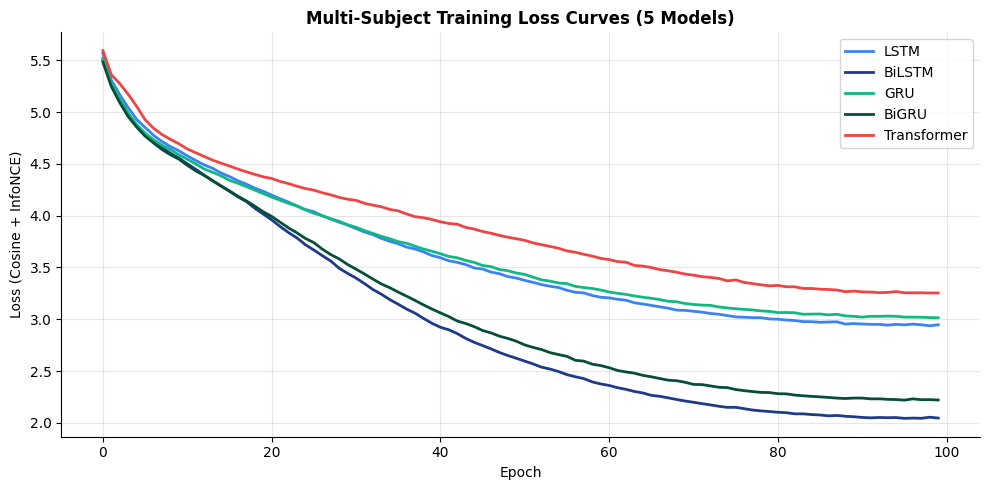

In [20]:
fig, ax = plt.subplots(figsize=(10, 5))
colors = {'LSTM': '#3B82F6', 'BiLSTM': '#1E3A8A', 'GRU': '#10B981', 'BiGRU': '#064E3B', 'Transformer': '#EF4444'}

for name, hist in histories.items():
    ax.plot(hist, color=colors[name], linewidth=2, label=name)

ax.set_xlabel('Epoch')
ax.set_ylabel('Loss (Cosine + InfoNCE)')
ax.set_title('Multi-Subject Training Loss Curves (5 Models)', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, 'training_loss_5models.png'), dpi=150, bbox_inches='tight')
plt.show()

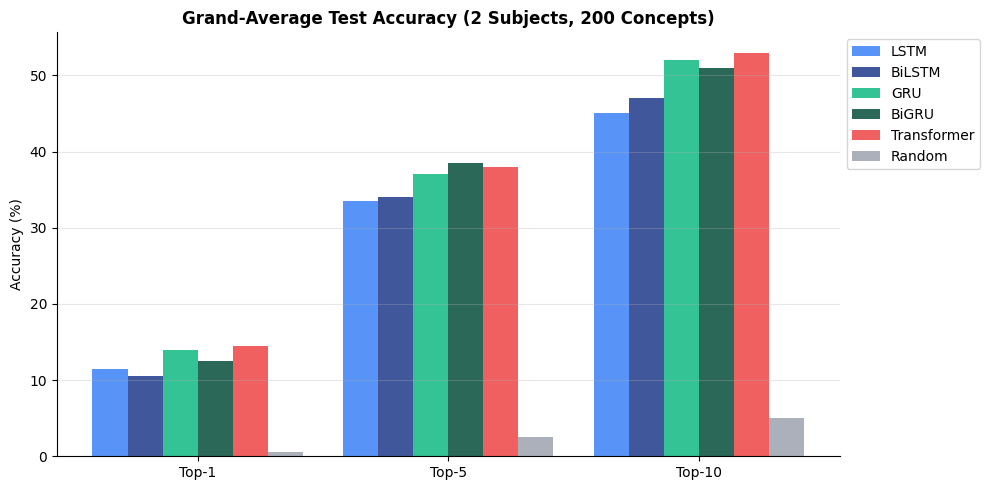

In [21]:
ks = [1, 5, 10]
x = np.arange(len(ks))
w = 0.14
offsets = [-2.5, -1.5, -0.5, 0.5, 1.5, 2.5]
models = ['LSTM', 'BiLSTM', 'GRU', 'BiGRU', 'Transformer']
bar_colors = [colors[m] for m in models] + ['#9CA3AF']

fig, ax = plt.subplots(figsize=(10, 5))
for i, name in enumerate(models):
    ax.bar(x + offsets[i]*w, [accuracies[name]['Grand_Avg'][k] for k in ks], w, label=name, color=bar_colors[i], alpha=0.85)

ax.bar(x + offsets[-1]*w, [random_1, random_5, random_10], w, label='Random', color=bar_colors[-1], alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels(['Top-1', 'Top-5', 'Top-10'])
ax.set_ylabel('Accuracy (%)')
ax.set_title(f'Grand-Average Test Accuracy ({len(SUBJECTS)} Subjects, 200 Concepts)', fontweight='bold')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
ax.grid(True, alpha=0.3, axis='y')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, 'accuracy_comparison_5models.png'), dpi=150, bbox_inches='tight')
plt.show()

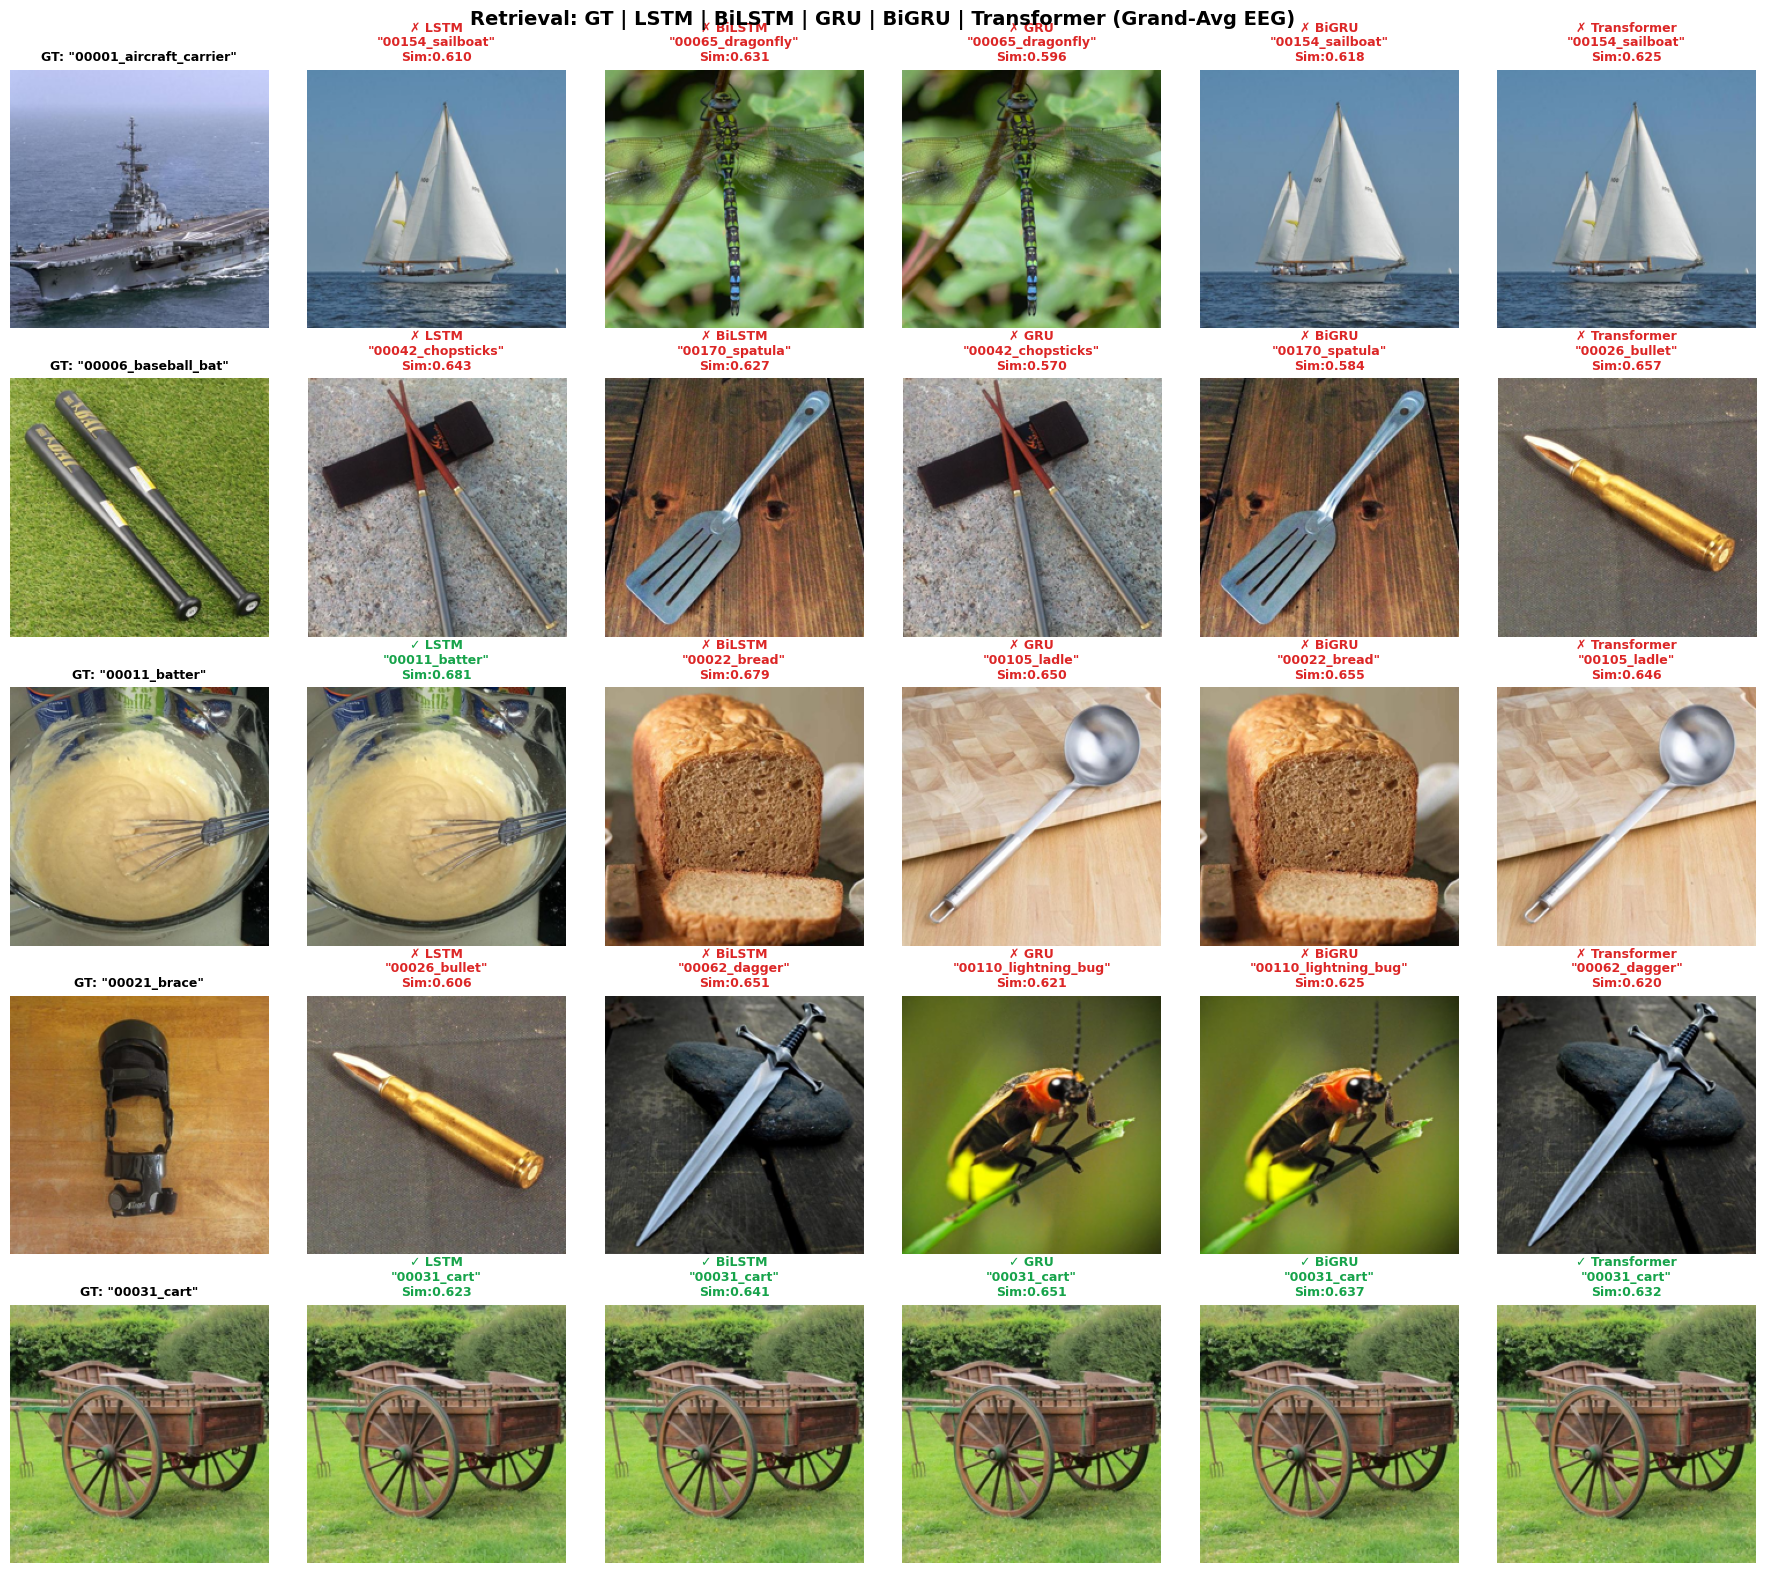

In [22]:
def retrieve_nearest(pred_embed, all_embeds, all_imgs):
    sims = cosine_similarity(pred_embed[np.newaxis], all_embeds)[0]
    idx = np.argmax(sims)
    return idx, sims[idx], all_imgs[idx][0]

DEMO = [0, 5, 10, 20, 30]
n = len(DEMO)

fig, axes = plt.subplots(n, 6, figsize=(18, n * 3.2))
fig.suptitle('Retrieval: GT | LSTM | BiLSTM | GRU | BiGRU | Transformer (Grand-Avg EEG)', fontsize=14, fontweight='bold')

for row, idx in enumerate(DEMO):
    concept = test_concepts[idx]

    # Ground Truth
    gt = Image.open(test_concept_imgs[idx][0]).convert('RGB').resize((224, 224))
    axes[row, 0].imshow(gt)
    axes[row, 0].set_title(f'GT: "{concept}"', fontsize=9, fontweight='bold')
    axes[row, 0].axis('off')

    # Models
    for col, name in enumerate(['LSTM', 'BiLSTM', 'GRU', 'BiGRU', 'Transformer'], 1):
        preds = predictions[name]['Grand_Avg']
        ri, rs, rp = retrieve_nearest(preds[idx], test_clip_embeds, test_concept_imgs)
        axes[row, col].imshow(Image.open(rp).convert('RGB').resize((224, 224)))
        ok = ri == idx
        mark = '\u2713' if ok else '\u2717'
        axes[row, col].set_title(f'{mark} {name}\n"{test_concepts[ri]}"\nSim:{rs:.3f}',
            fontsize=9, fontweight='bold', color='#16A34A' if ok else '#DC2626')
        axes[row, col].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(BASE_DIR, 'retrieval_comparison_5models.png'), dpi=150, bbox_inches='tight')
plt.show()

## Step 4: Save Predicted Vectors for Every Subject & Grand Average

In [23]:
best_name = max(models_config.keys(), key=lambda k: accuracies[k]['Grand_Avg'][10])

# Save predicted vectors for each subject and the grand-average
for name in models_config.keys():
    for sub in SUBJECTS:
        np.save(os.path.join(VEC_DIR, f'{sub}_{name.lower()}_pred_embeddings.npy'), predictions[name][sub])
    np.save(os.path.join(VEC_DIR, f'grand_avg_{name.lower()}_pred_embeddings.npy'), predictions[name]['Grand_Avg'])

np.save(os.path.join(VEC_DIR, 'test_clip_gt_embeddings.npy'), test_clip_embeds)
np.save(os.path.join(VEC_DIR, 'test_concept_names.npy'), np.array(test_concepts))

print(f'Vectors saved to {VEC_DIR}/ for ALL subjects ({", ".join(SUBJECTS)}) and Grand Average!')
print(f'Vector dimension: {CLIP_DIM} (native CLIP ViT-L/14 image space)')
print(f'Best Model Overall (Grand-Avg Top-10): {best_name} ({accuracies[best_name]["Grand_Avg"][10]:.1f}%)')

Vectors saved to /content/vectors/ for ALL subjects (sub-01, sub-02) and Grand Average!
Vector dimension: 768 (native CLIP ViT-L/14 image space)
Best Model Overall (Grand-Avg Top-10): Transformer (53.0%)


## Step 5: Package Ranked Models & Download ArchiveAutomatically packages all trained models ranked by performance, along with their prediction vectors and inference configuration, and downloads the `.zip` to your computer.

In [24]:
EXPORT_DIR = os.path.join(BASE_DIR, 'neuraldream_export')
EXPORT_CKPT_DIR = os.path.join(EXPORT_DIR, 'ranked_checkpoints')
os.makedirs(EXPORT_CKPT_DIR, exist_ok=True)

# Rank models based on Grand-Average Test Top-10 accuracy
ranked_models = sorted(models_config.keys(), key=lambda m: accuracies[m]['Grand_Avg'][10], reverse=True)

print("=" * 60)
print("  PACKAGING MODEL CHECKPOINTS BY RANK (GRAND-AVG TEST TOP-10)")
print("=" * 60)

model_metadata = {}
for rank, name in enumerate(ranked_models, start=1):
    top1 = accuracies[name]['Grand_Avg'][1]
    top10 = accuracies[name]['Grand_Avg'][10]
    src_ckpt = os.path.join(CKPT_DIR, f'{name.lower()}_best.pt')

    # Save with rank prefix
    dst_name = f'rank{rank}_{name}_best.pt'
    dst_ckpt = os.path.join(EXPORT_CKPT_DIR, dst_name)

    if os.path.exists(src_ckpt):
        shutil.copy2(src_ckpt, dst_ckpt)

    model_metadata[f'rank_{rank}'] = {
        'model_name': name,
        'checkpoint_file': dst_name,
        'block_size': BEST_BS_TRANS if name == 'Transformer' else BEST_BS_RNN,
        'clip_dim': CLIP_DIM,
        'grand_avg_top1': f'{top1:.2f}%',
        'grand_avg_top10': f'{top10:.2f}%',
        'per_subject_top10': {sub: f"{accuracies[name][sub][10]:.2f}%" for sub in SUBJECTS}
    }
    prefix = "🏆 BEST MODEL ->" if rank == 1 else f"  Rank {rank}      ->"
    print(f"{prefix} {dst_name:<30} (Grand-Avg Top-1: {top1:.1f}% | Top-10: {top10:.1f}%)")

# Save inference configuration
metadata_path = os.path.join(EXPORT_DIR, 'inference_config.json')
with open(metadata_path, 'w') as f:
    json.dump(model_metadata, f, indent=4)

# Copy vectors
dst_vec_dir = os.path.join(EXPORT_DIR, 'vectors')
if os.path.exists(dst_vec_dir):
    shutil.rmtree(dst_vec_dir)
shutil.copytree(VEC_DIR, dst_vec_dir)

# Zip export directory
zip_path = os.path.join(BASE_DIR, 'neuraldream_models_and_vectors')
print("\nCompressing all assets into zip...")
shutil.make_archive(zip_path, 'zip', EXPORT_DIR)
full_zip_file = f'{zip_path}.zip'

print(f"Archive ready: {full_zip_file} ({os.path.getsize(full_zip_file) / (1024*1024):.1f} MB)")

# Trigger Colab browser download (if on Colab)
try:
    from google.colab import files
    print("Starting browser download now...")
    files.download(full_zip_file)
except ImportError:
    print(f"Archive saved locally at: {full_zip_file}")

  PACKAGING MODEL CHECKPOINTS BY RANK (GRAND-AVG TEST TOP-10)
🏆 BEST MODEL -> rank1_Transformer_best.pt      (Grand-Avg Top-1: 14.5% | Top-10: 53.0%)
  Rank 2      -> rank2_GRU_best.pt              (Grand-Avg Top-1: 14.0% | Top-10: 52.0%)
  Rank 3      -> rank3_BiGRU_best.pt            (Grand-Avg Top-1: 12.5% | Top-10: 51.0%)
  Rank 4      -> rank4_BiLSTM_best.pt           (Grand-Avg Top-1: 10.5% | Top-10: 47.0%)
  Rank 5      -> rank5_LSTM_best.pt             (Grand-Avg Top-1: 11.5% | Top-10: 45.0%)

Compressing all assets into zip...
Archive ready: /content/neuraldream_models_and_vectors.zip (63.4 MB)
Starting browser download now...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
!pip install -q diffusers accelerate

Loading Stable Diffusion Image Variation Pipeline (FP16)...


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/392 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--lambda--sd-image-variations-diffusers/snapshots/a2a13984e57db80adcc9e3f85d568dcccb9b29fc/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--lambda--sd-image-variations-diffusers/snapshots/a2a13984e57db80adcc9e3f85d568dcccb9b29fc/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--lambda--sd-image-variations-diffusers/snapshots/a2a13984e57db80adcc9e3f85d568dcccb9b29fc/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--lambda--sd-image-variations-diffusers/snapshots/a2a13984e57db80adcc9e3f85d568dcccb9b29fc/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Using decoded thoughts from Best Model: 🏆 Transformer


... (5 outputs left out)

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]


✅ All thought images generated! Saved figure to /content/eeg_diffusion_reconstructions.png


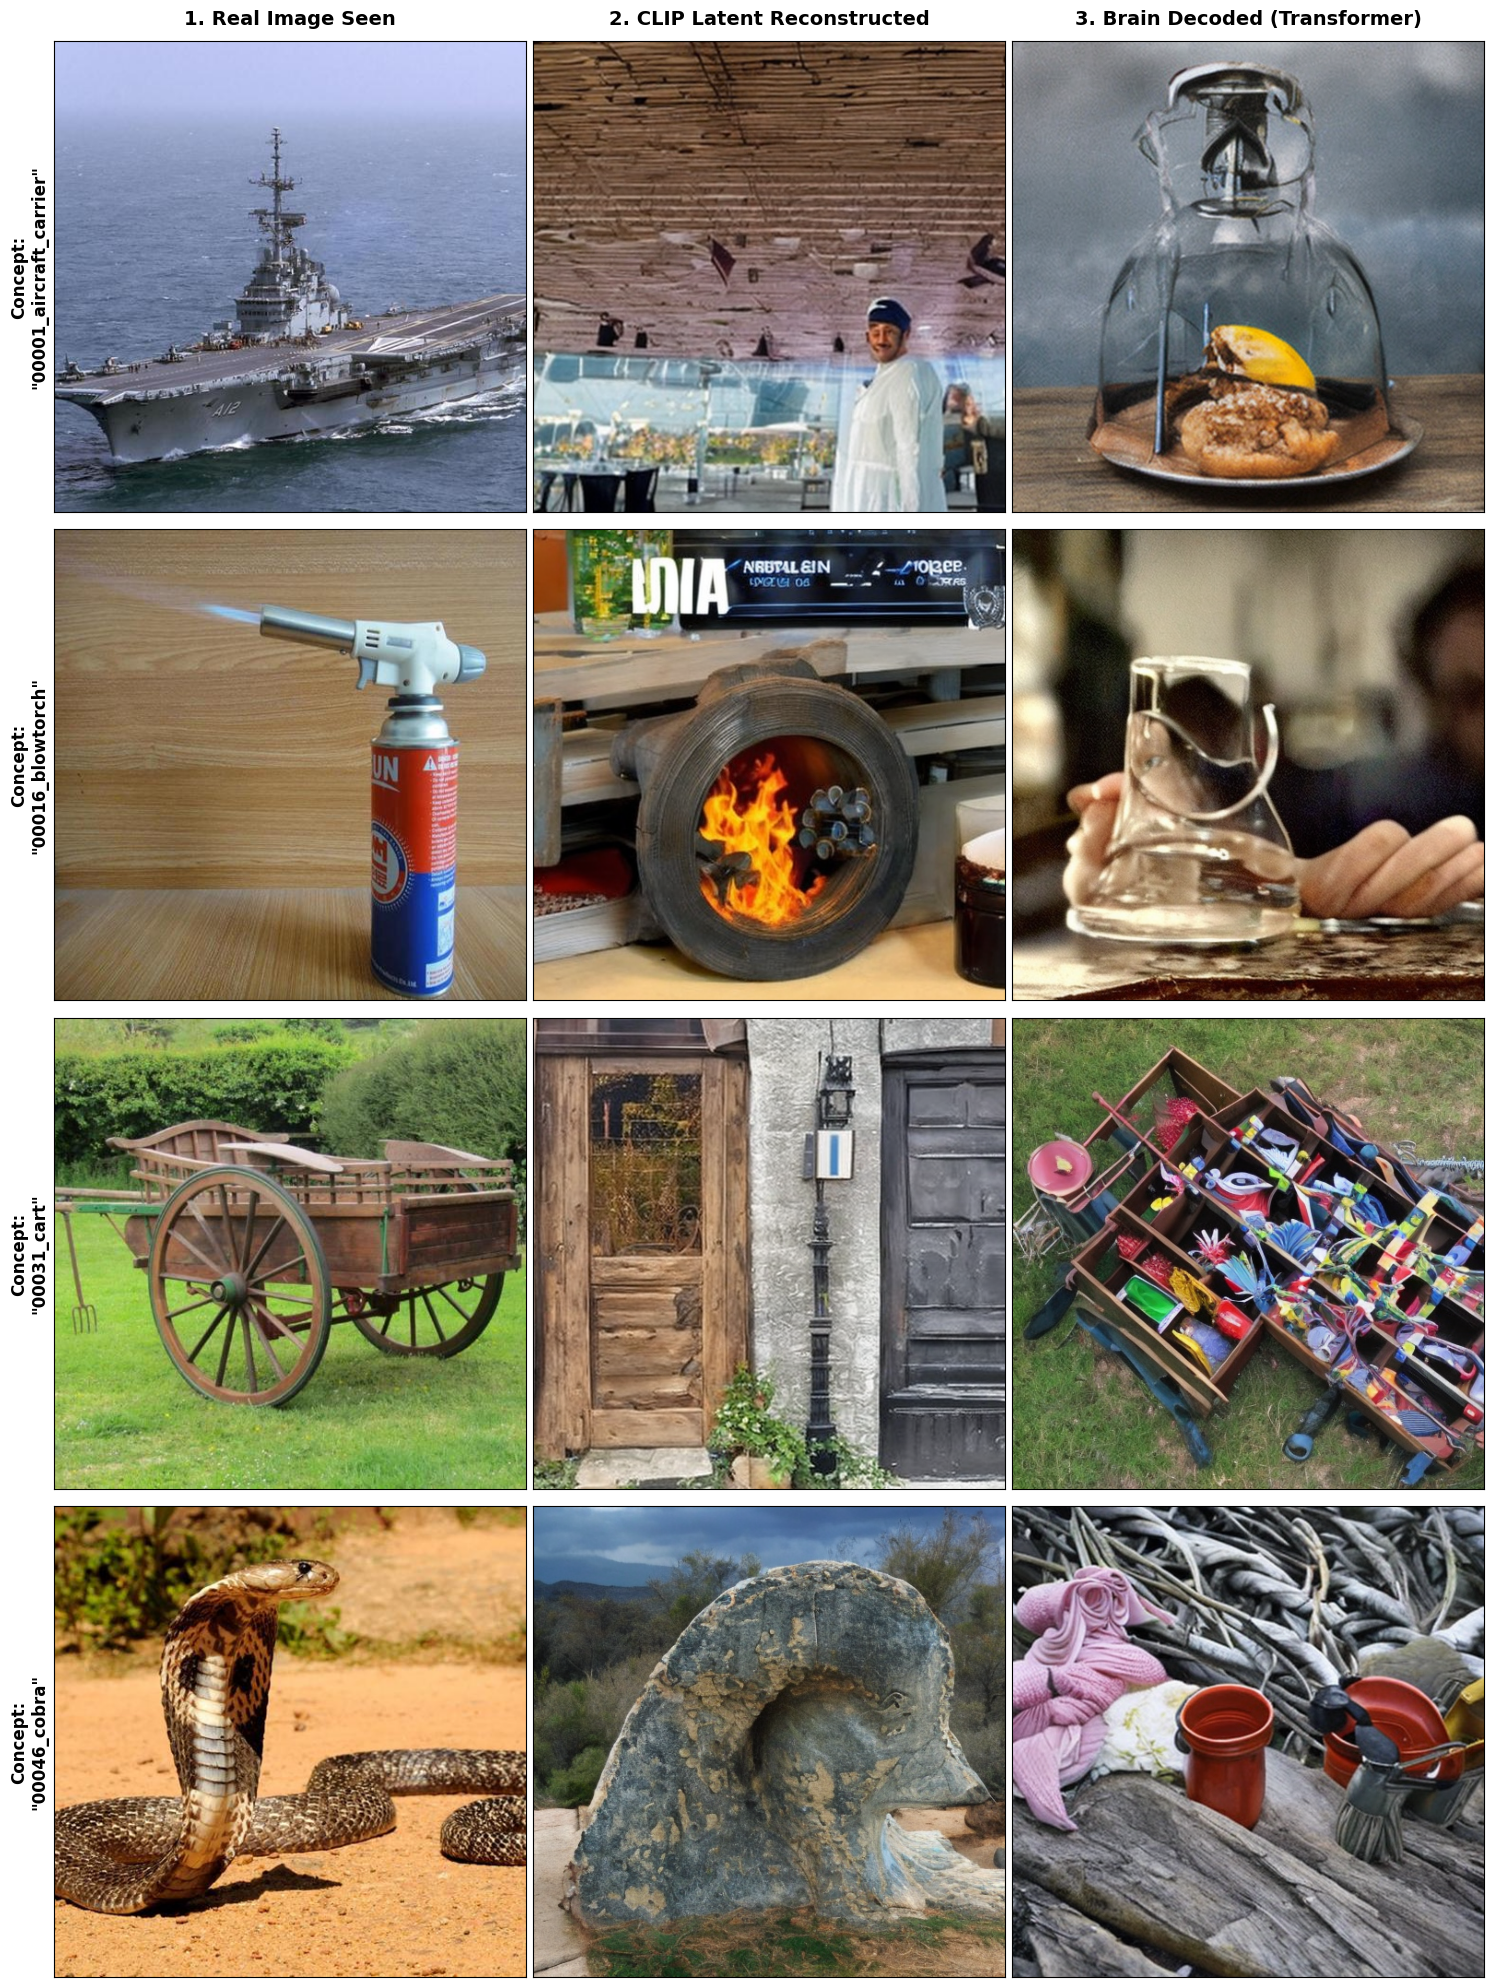

In [28]:
# ── STEP 6: EEG-to-Image Generation via Diffusion ──────────
import os
import types
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from diffusers import StableDiffusionImageVariationPipeline

# 1. Load the Image-Conditioned Diffusion Pipeline (FP16)
print("Loading Stable Diffusion Image Variation Pipeline (FP16)...")
diff_device = "cuda" if torch.cuda.is_available() else "cpu"

pipe = StableDiffusionImageVariationPipeline.from_pretrained(
    "lambda/sd-image-variations-diffusers",
    revision="v2.0",
    torch_dtype=torch.float16 if diff_device == "cuda" else torch.float32
).to(diff_device)

pipe.safety_checker = None  # Disable safety filter to avoid false black images

# 2. Hook the pipeline to accept our 768-D brainwave vectors directly
def custom_encode_image(self, image, device, num_images_per_prompt, do_classifier_free_guidance):
    # If the input is already our decoded (1, 768) EEG vector, use it directly
    if isinstance(image, torch.Tensor) and image.ndim in [2, 3]:
        image_embeddings = image.to(device=device, dtype=self.unet.dtype)
    else:
        # Standard fallback for PIL photos
        dtype = next(self.image_encoder.parameters()).dtype
        if not isinstance(image, torch.Tensor):
            image = self.feature_extractor(images=image, return_tensors="pt").pixel_values
        image = image.to(device=device, dtype=dtype)
        image_embeddings = self.image_encoder(image).image_embeds

    if image_embeddings.ndim == 2:
        image_embeddings = image_embeddings.unsqueeze(1)

    bs_embed, seq_len, _ = image_embeddings.shape
    image_embeddings = image_embeddings.repeat(1, num_images_per_prompt, 1)
    image_embeddings = image_embeddings.view(bs_embed * num_images_per_prompt, seq_len, -1)

    if do_classifier_free_guidance:
        uncond_embeddings = torch.zeros_like(image_embeddings)
        image_embeddings = torch.cat([uncond_embeddings, image_embeddings])

    return image_embeddings

pipe._encode_image = types.MethodType(custom_encode_image, pipe)

# 3. Pick the Best Model's predictions & Ground Truth
best_model_name = max(models_config.keys(), key=lambda k: accuracies[k]['Grand_Avg'][10])
print(f"Using decoded thoughts from Best Model: 🏆 {best_model_name}")

eeg_latents = predictions[best_model_name]['Grand_Avg']  # Shape: (200, 768)
gt_latents = test_clip_embeds                             # Shape: (200, 768)

# 4. Select 4 test concepts to decode and visualize
demo_indices = [0, 15, 30, 45]  # Any test concepts between 0 and 199

fig, axes = plt.subplots(len(demo_indices), 3, figsize=(15, 5 * len(demo_indices)))
columns = ["1. Real Image Seen", "2. CLIP Latent Reconstructed", f"3. Brain Decoded ({best_model_name})"]

for col_idx, col_name in enumerate(columns):
    axes[0, col_idx].set_title(col_name, fontsize=14, fontweight="bold", pad=12)

for row, idx in enumerate(demo_indices):
    concept_name = test_concepts[idx]

    # A. Original Ground Truth Photo
    gt_photo = Image.open(test_concept_imgs[idx][0]).convert("RGB").resize((512, 512))
    axes[row, 0].imshow(gt_photo)
    axes[row, 0].set_ylabel(f'Concept:\n"{concept_name}"', fontsize=12, fontweight="bold")
    axes[row, 0].set_xticks([])
    axes[row, 0].set_yticks([])

    # B. Generate from Ground-Truth CLIP vector
    gt_tensor = torch.tensor(gt_latents[idx:idx+1], dtype=pipe.unet.dtype).to(diff_device)
    with torch.autocast(diff_device):
        gt_gen_img = pipe(
            image=gt_tensor,
            num_inference_steps=25,
            guidance_scale=7.5
        ).images[0]

    axes[row, 1].imshow(gt_gen_img)
    axes[row, 1].set_xticks([])
    axes[row, 1].set_yticks([])

    # C. Generate directly from the EEG Brainwave vector
    eeg_tensor = torch.tensor(eeg_latents[idx:idx+1], dtype=pipe.unet.dtype).to(diff_device)
    with torch.autocast(diff_device):
        eeg_gen_img = pipe(
            image=eeg_tensor,
            num_inference_steps=25,
            guidance_scale=7.5
        ).images[0]

    axes[row, 2].imshow(eeg_gen_img)
    axes[row, 2].set_xticks([])
    axes[row, 2].set_yticks([])

plt.tight_layout()
save_path = os.path.join(BASE_DIR, 'eeg_diffusion_reconstructions.png')
plt.savefig(save_path, dpi=200, bbox_inches='tight')
print(f"\n✅ All thought images generated! Saved figure to {save_path}")
plt.show()